In [1]:
# import packages
from pathlib import Path
import pandas as pd
import geopandas as gpd
import seaborn as sns

In [2]:
# file path to import data
root_fldr = Path.cwd().parent
raw_fldr = root_fldr / 'data' / 'raw' 
processed_fldr = root_fldr / 'data' / 'processed'
fire_shp= raw_fldr / 'cal_fire_historical_data' / 'California_Historic_Fire_Perimeters_-6302641808644124224.zip'

In [3]:
# Read the shapefile
wildfires_gdf = gpd.read_file(filename = fire_shp)
wildfires_gdf.head()

,YEAR_,STATE,AGENCY,UNIT_ID,FIRE_NAME,INC_NUM,ALARM_DATE,CONT_DATE,CAUSE,C_METHOD,OBJECTIVE,GIS_ACRES,COMMENTS,COMPLEX_NA,IRWINID,FIRE_NUM,COMPLEX_ID,DECADES,geometry
0,2025,CA,USF,LPF,GIFFORD,00002181,2025-08-01,2025-10-14,14,3,1,131614.0,NaN,NaN,{08A6358F-8301-4093-9988-E265C8F6F0A9},NaN,NaN,2020-2025,"MULTIPOLYGON (((-13401376.178 4203562.931, -13..."
1,2025,CA,USF,LPF,MADRE,00001817,2025-07-02,2025-07-26,14,7,1,80779.1,NaN,NaN,{1AB682F7-CC0F-4DCE-87A4-FA4A9B67AB05},NaN,NaN,2020-2025,"POLYGON ((-13363729.916 4190093.666, -13363730..."
2,2025,CA,USF,SNF,GARNET,00001684,2025-08-24,2025-10-23,1,3,1,60019.2,NaN,NaN,{68B988A1-C190-4F0C-9BEA-A658D389D167},NaN,NaN,2020-2025,"MULTIPOLYGON (((-13246213.777 4426752.325, -13..."
3,2025,CA,CDF,FKU,SALT,00018739,2025-09-02,2025-09-17,1,7,1,25553.5,Park incident clipped out per BEU,NaN,{7F4A1474-6439-44F3-8F0D-083DCFD33639},NaN,NaN,2020-2025,"POLYGON ((-13397839.121 4293483.6, -13397810.1..."
4,2025,CA,CDF,LDF,PALISADES,00000738,2025-01-07,2025-01-31,14,7,1,23448.9,NaN,NaN,{A7EA5D21-F882-44B8-BF64-44AB11059DC1},NaN,NaN,2020-2025,"MULTIPOLYGON (((-13193558.265 4032826.468, -13..."


In [4]:
wildfires_gdf.columns

Index(['YEAR_', 'STATE', 'AGENCY', 'UNIT_ID', 'FIRE_NAME', 'INC_NUM',
       'ALARM_DATE', 'CONT_DATE', 'CAUSE', 'C_METHOD', 'OBJECTIVE',
       'GIS_ACRES', 'COMMENTS', 'COMPLEX_NA', 'IRWINID', 'FIRE_NUM',
       'COMPLEX_ID', 'DECADES', 'geometry'],
      dtype='str')

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

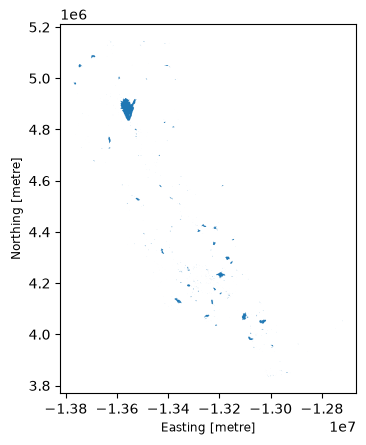

In [7]:
fires_2024 = wildfires_gdf.query('YEAR_ == 2024')
fires_2024.plot()

In [ ]:
query_url = (
    f"{ca_zipcode_url}/query"
    "?where=STATE%3D'CA'"     # filter server-side to California
    "&outFields=*"            # all attribute columns
    "&outSR=4326"             # lat/lon
    "&f=geojson"
)
ca_zips = gpd.read_file(query_url)